# Conformalized quantile regression

CQR conformalizes a forecaster that already emits quantiles. Instead of building
a band out of absolute residuals, it takes the model's own quantile forecast and
corrects it just enough to hit the coverage target.

## What it does

The forecaster supplies a lower and upper quantile, `q_lo` and `q_hi`, at levels
`alpha/2` and `1 - alpha/2`. The nonconformity score asks how far outside that
band the truth fell:

```
E = max(q_lo - y, y - q_hi)
```

`E` is negative when the truth landed comfortably inside, positive when it fell
outside. Take the exact conformal quantile `Q` of the calibration `E`s and widen
— or, if the model was over-cautious, **narrow** — the band:

```
[q_lo - Q, q_hi + Q]
```

That negative case is the whole point. Split conformal can only add width. CQR
inherits the *shape* of the model's quantile forecast — wide at a volatile
season, narrow at a calm one — and conformal calibration only fixes its overall
level.

## Worked example

`AutoETS` produces analytical prediction intervals, which `StatsForecastAdapter`
exposes as quantiles. That makes it quantile-capable, so it can back CQR.

::: {.callout-important}
## Not every adapter can

`ConformalizedQuantileRegression` declares `SupportsQuantiles` in its
`REQUIRED_CAPABILITIES`, and the check runs where the forecaster is bound — the
first thing both `calibrate` and `calibrate_cv` do. `MLForecastAdapter` does not
implement quantiles, so calibrating CQR on one raises `UnsupportedCapability`
before any forecasting happens, rather than failing later inside `predict`.
`NeuralForecastAdapter` supports it only when the model's loss is a quantile loss
such as `MQLoss` — it overrides `supports()` to inspect the loss, so the same
class passes or fails depending on how it was trained.
:::

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS

from conformalforecast import ConformalizedQuantileRegression, SplitConformal
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import evaluate

HORIZON, SEASON, ALPHA = 12, 12, 0.1

df = pd.read_csv("nbs/data/air_passengers.csv", parse_dates=["ds"])
panel = df["y"].to_numpy()[None, :]
cutoff = panel.shape[1] - HORIZON
train_df = df.iloc[:cutoff].reset_index(drop=True)

sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="MS", n_jobs=1)
sf.fit(train_df)
forecaster = StatsForecastAdapter(
    sf=sf, train_df=train_df, horizon=HORIZON, freq="MS", model_name="AutoETS"
)

cqr = ConformalizedQuantileRegression(alpha=ALPHA)
cqr_fitted = cqr.calibrate_cv(forecaster, n_windows=24)
print("quantile levels:", cqr.quantile_levels)

quantile levels: [0.05 0.95]


`calibrate_cv` noticed that the method `CONSUMES_QUANTILES` and asked the adapter for a *quantile* cross-validation
rather than a point one. You never request that yourself.

::: {.callout-warning}
## statsforecast quantile rules

Quantiles must arrive in symmetric pairs, and `q == 0.5` is rejected — the level
API statsforecast exposes has no median column. `alpha=0.1` becomes the pair
`(0.05, 0.95)` automatically, which is what `quantile_levels` shows above. You only
choose levels yourself when you pass `symmetric=False` with explicit `alpha_lo`
and `alpha_hi`.
:::

## What conformalizing changed

Compare three bands on the same axis: the raw `AutoETS` quantiles, the same
quantiles after CQR, and a split-conformal band for reference.

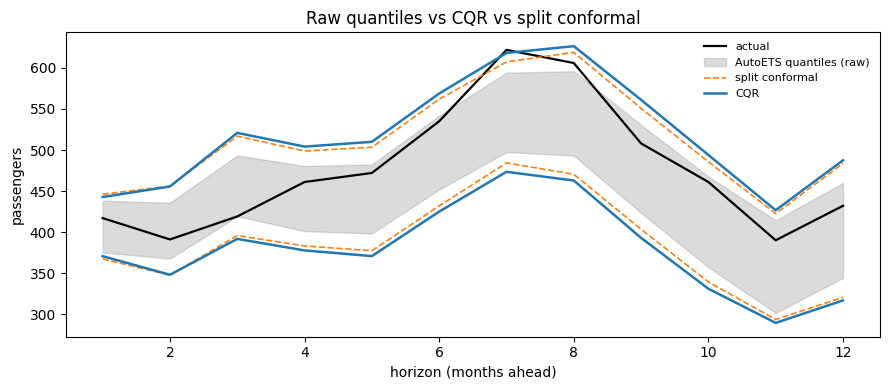

In [ ]:
prediction = cqr_fitted.predict(panel[:, :cutoff])

# The model's own quantiles, before any conformal correction.
raw = forecaster.predict_quantiles(panel[:, :cutoff], cqr.quantile_levels)
raw_lo, raw_hi = raw[0, 0], raw[0, 1]

split = SplitConformal(alpha=ALPHA)
split_fitted = split.calibrate_cv(forecaster, n_windows=24)
split_interval = split_fitted.predict(panel[:, :cutoff]).interval[0, 0]

steps = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(steps, panel[0, cutoff:], color="k", lw=1.6, label="actual")
ax.fill_between(steps, raw_lo, raw_hi, color="0.6", alpha=0.35, label="AutoETS quantiles (raw)")
ax.plot(steps, split_interval[:, 0], color="C1", lw=1.2, ls="--", label="split conformal")
ax.plot(steps, split_interval[:, 1], color="C1", lw=1.2, ls="--")
ax.plot(steps, prediction.interval[0, 0, :, 0], color="C0", lw=1.8, label="CQR")
ax.plot(steps, prediction.interval[0, 0, :, 1], color="C0", lw=1.8)
ax.set_xlabel("horizon (months ahead)")
ax.set_ylabel("passengers")
ax.set_title("Raw quantiles vs CQR vs split conformal")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()

In [ ]:
widths = {
    "AutoETS quantiles (raw)": raw_hi - raw_lo,
    "CQR": prediction.interval[0, 0, :, 1] - prediction.interval[0, 0, :, 0],
    "split conformal": split_interval[:, 1] - split_interval[:, 0],
}
for name, w in widths.items():
    print(f"{name:26s} mean width {w.mean():7.1f}   at h=1 {w[0]:6.1f}   at h=12 {w[-1]:6.1f}")

AutoETS quantiles (raw)    mean width    92.0   at h=1   63.0   at h=12  115.7
CQR                        mean width   138.9   at h=1   72.1   at h=12  170.7
split conformal            mean width   128.2   at h=1   78.8   at h=12  163.2


The raw quantiles and the CQR band have the same *shape* — CQR pushed each edge
out by one constant per horizon step, which is exactly what the score above
does. It kept the seasonal bulge around step 7 that the raw quantiles already
had.

Here it widened: `AutoETS`'s analytical 90% band averaged 92 passengers wide and
was too confident, so the conformal quantile came out positive. Had the model
been over-cautious the score would have been negative and CQR would have pulled
the band *in* — the move split conformal cannot make, because an absolute
residual is never negative.

## Measured coverage

In [ ]:
N_HOLDOUT = 4
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = panel.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(panel[:, :end])
    truths.append(panel[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

for name, fitted in [("CQR", cqr_fitted), ("SplitConformal", split_fitted)]:
    report = evaluate(fitted, histories, truths)
    print(
        f"{name:16s} coverage {report.marginal_coverage:6.1%}   "
        f"width {report.mean_interval_width:7.1f}   "
        f"Winkler {report.mean_winkler_score:7.1f}"
    )

CQR              coverage  93.8%   width   126.6   Winkler   141.9


SplitConformal   coverage  93.8%   width   128.2   Winkler   149.2


Both hit the same coverage, and here CQR does it slightly narrower — so its
Winkler score, which charges for width and for misses on one scale, comes out
lower.

That reverses the single-window comparison above, where CQR came out *wider*
(138.9 against 128.2). Split conformal's width is fixed by its score quantile,
so it is the same 128.2 in every window; CQR's rides on the model's own
quantiles and moves window by window. Averaged over the four holdout windows
it lands narrower, even though it was wider in the last one.

That is the shape advantage paying off: on a series whose uncertainty is not
constant across the horizon, inheriting the model's profile beats a flat band.

## Asymmetric intervals

By default CQR requests the `alpha/2` and `1 - alpha/2` quantiles from the
forecaster. When the cost of being too low differs from the cost of being too
high — inventory, staffing, capacity planning — request an off-centre pair with
`symmetric=False`. The levels move the band's width and position, not its
validity: one conformal quantile of the CQR score is added to both sides, so the
guarantee is joint coverage `1 - alpha` whatever the levels are, with no
per-tail guarantee. By convention the pair still satisfies
`alpha_lo + (1 - alpha_hi) = alpha`:

```python
cqr = ConformalizedQuantileRegression(
    alpha=0.1, symmetric=False, alpha_lo=0.02, alpha_hi=0.92
)
fitted = cqr.calibrate_cv(forecaster, n_windows=24)
```

::: {.callout-warning}
## No shipped Nixtla adapter can serve asymmetric levels in v0.1

That snippet is not executed on this page, because it would fail with any of the
three Nixtla adapters — statsforecast, mlforecast **and** neuralforecast alike.

The constraint is not in CQR. The method accepts any
`0 < alpha_lo < 0.5 < alpha_hi < 1` with `alpha_lo + (1 - alpha_hi) = alpha`, and its array
surface never learns which levels produced its inputs. It is in the bridge to the Nixtla
libraries: all three expose intervals through an integer `level` API, where
`level=90` means the 5th *and* 95th percentiles inseparably. The shared helper
`adapters/_nixtla_common.quantiles_to_levels` therefore rejects any quantile
whose mirror is absent:

```
ValueError: Quantile 0.02 requires its symmetric pair 0.98 to also be
present in quantiles. Got [0.02, 0.92].
```

Training a neuralforecast model with `MQLoss(quantiles=[0.02, 0.92])` does not
help — the adapter still requests those quantiles through `level=`, and raises
the same error before the model is consulted.

What does work is an adapter that implements `SupportsQuantiles` directly and
serves arbitrary levels, bypassing the level API. That is a dozen lines on top of
your own model; `tests/helpers.py` has a working example, and
[Adapters](../adapters/index.html) covers the contract. Until a Nixtla adapter grows a
non-level quantile path, that is the only route to an asymmetric interval *from
CQR*.

It is not the only route to an asymmetric conformal interval.
[`SplitConformal(symmetric=False, alpha_lo=..., alpha_hi=...)`](split.html) takes one
one-sided conformal quantile of the **signed** residual per tail, so it needs no
quantile capability at all and works through every adapter, the three Nixtla ones
included. What it buys is different, though: its two offsets are constants added
to the point forecast, so it corrects a forecaster that is *consistently* biased,
while CQR's quantiles track skew that varies with each input. Reach for it when
one tail carries the real cost and a fixed shift is enough; reach for CQR when
the asymmetry itself depends on the features.
:::

## When not to use it

- **Your forecaster has no quantiles.** Most gradient-boosting setups through
  mlforecast do not, and CQR will refuse the moment you calibrate. Use [split
  conformal](split.html), or [SPCI](spci.html) if you want varying width without a
  quantile-capable model.
- **Your coverage drifts over time.** CQR is offline: it calibrates once. Pair
  the diagnosis with [ACI](aci.html) or [NexCP](nexcp.html).

## References
Y. Romano, E. Patterson, and E. J. Candès, “Conformalized Quantile Regression,” 2019. [Online]. Available: https://arxiv.org/abs/1905.03222.

## Next

- [ACI](aci.html) — the first online method, for coverage that drifts.
- [SPCI](spci.html) — varying width from a residual model rather than a quantile model.
- [Methods overview](index.html) — the decision guide.